# Buổi G2: Huấn luyện mạng nơ-ron đúng cách, tốc độ học, dừng sớm, phanh

**Hiện trường.** Chị Hạnh dùng mạng nơ-ron nhận diện chữ số viết tay (64 điểm ảnh). Lần chạy đầu cho điểm khá, nhưng chạy lại thì điểm khác, có lần máy báo "chưa hội tụ", có lần điểm học 100% mà điểm thi thấp hơn. Chị hỏi: *mạng nơ-ron có "tính nết" thế nào và ta điều khiển nó ra sao?*

Buổi này dạy bốn núm vặn của việc huấn luyện: **tốc độ học** (bước dịch mỗi lần chỉnh trọng số), **dừng sớm** (dừng khi điểm trên tập kiểm bắt đầu không tốt lên), **phanh `alpha`** (phạt trọng số lớn, như Ridge ở B6), và **nhiều hạt giống** (chạy nhiều mạng rồi lấy trung bình, như rừng ở E2).

**Ẩn dụ:** huấn luyện giống xuống núi trong sương mù để tìm thung lũng thấp nhất. Bước quá nhỏ thì đi mãi không tới; bước quá lớn thì nhảy qua thung lũng; đi quá lâu thì "thuộc lòng" từng hòn đá trên đường (học thừa). Dừng sớm là biết lúc nào nên ngừng.

**Mindset của người làm dữ liệu:** mỗi lần huấn luyện là một lần thử có may rủi. Báo cáo một con số từ **một** lần chạy là báo cáo may rủi.

**Lưu ý:** dùng `load_digits` của sklearn; dùng để học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: cùng một mạng, hai lần chạy, hai điểm |
| Chặng 1 | Tốc độ học: bước nhỏ, vừa, lớn |
| Chặng 2 | Dừng sớm bằng tập kiểm |
| Chặng 3 | Phanh alpha (phạt trọng số lớn) |
| Chặng 4 | Nhiều hạt giống: lấy trung bình |
| Chặng 5 | Dữ liệu ít thì mạng học thừa |

## Chặng 0: Thấy ngay, hai lần chạy hai điểm

**Câu hỏi:** chạy cùng một mạng với hai hạt giống thì điểm khác nhau bao nhiêu?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
import warnings, time
from sklearn.exceptions import ConvergenceWarning
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
digits = load_digits()
X_tr, X_te, y_tr, y_te = train_test_split(digits.data, digits.target, test_size=0.25, random_state=0, stratify=digits.target)
scaler = StandardScaler().fit(X_tr)
Xs_tr, Xs_te = scaler.transform(X_tr), scaler.transform(X_te)

def fit_quiet(**kw):
    params = dict(hidden_layer_sizes=(64,), max_iter=300, random_state=0)
    params.update(kw)
    m = MLPClassifier(**params)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        m.fit(Xs_tr, y_tr)
    return m

seed_res = {}
for seed in (0, 1):
    m = fit_quiet(random_state=seed)
    seed_res[seed] = (m.score(Xs_tr, y_tr), m.score(Xs_te, y_te), m.n_iter_)
    print("seed", seed, "| train", round(seed_res[seed][0], 3), "| test", round(seed_res[seed][1], 3), "| epochs run", seed_res[seed][2])

seed 0 | train 1.0 | test 0.973 | epochs run 172


seed 1 | train 1.0 | test 0.976 | epochs run 173


**Giải thích từng dòng**

- `load_digits()`: 1797 ảnh chữ số 8x8 (F4, C7). Cột cùng thang 0 đến 16 nhưng ta vẫn chuẩn hóa: mạng nơ-ron luôn thích dữ liệu chuẩn hóa (G1).
- `def fit_quiet(**kw)`: hàm nhỏ huấn luyện mạng và tạm tắt cảnh báo "chưa hội tụ" để bảng kết quả không bị ngập; ta sẽ **tự đếm** số lần chưa hội tụ ở các chặng sau.
- `MLPClassifier(hidden_layer_sizes=(64,), max_iter=300)`: một tầng ẩn 64 nơ-ron, tối đa 300 epoch. Mặc định bộ chỉnh là `adam`.
- `m.n_iter_`: số epoch thực tế đã chạy.

**Cách đọc.**
- **Con số:** hạt giống 0: học **100,0%**, thi **97,3%**; hạt giống 1: học **100,0%**, thi **97,6%**. Số epoch đã chạy: 172 và 173 (tối đa 300).
- **Bức tranh:** điểm học gần như tuyệt đối còn điểm thi thấp hơn một chút: mạng bắt đầu thuộc lòng tập học. Hai hạt giống cho hai điểm thi hơi khác nhau.
- **Câu hỏi tiếp:** bốn núm vặn nào kiểm soát được "tính nết" này? Ta xét lần lượt.

**Mang về chặng 1:** một lần chạy chưa đủ để kết luận; điểm học chói và điểm thi kém là dấu hiệu học thừa.

## Chặng 1: Tốc độ học

**Câu hỏi:** bước dịch mỗi lần chỉnh trọng số nên lớn cỡ nào?

               epochs run  hit max_iter  final loss   test
learning_rate                                             
0.0001                300          True      0.1250  0.967
0.0010                172         False      0.0065  0.973
0.0100                 45         False      0.0013  0.973
0.1000                 29         False      0.1582  0.938
1.0000                 21         False      0.6218  0.944


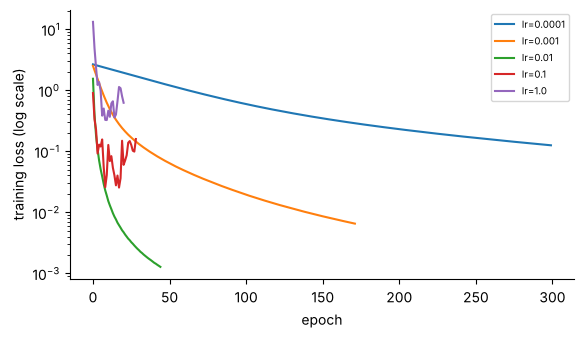

In [3]:
rows, curves = [], {}
for lr in [0.0001, 0.001, 0.01, 0.1, 1.0]:
    m = fit_quiet(learning_rate_init=lr)
    curves[lr] = m.loss_curve_
    rows.append({"learning_rate": lr, "epochs run": m.n_iter_, "hit max_iter": m.n_iter_ >= 300, "final loss": round(m.loss_curve_[-1], 4), "test": round(m.score(Xs_te, y_te), 3)})
lr_table = pd.DataFrame(rows).set_index("learning_rate")
print(lr_table.to_string())
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for lr, c in curves.items():
    ax.plot(c, label=f"lr={lr}")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("training loss (log scale)"); ax.legend(fontsize=7)
plt.show()

**Giải thích từng dòng**

- `learning_rate_init=lr`: tốc độ học ban đầu của bộ chỉnh `adam`: bước dịch mỗi lần chỉnh trọng số.
- `m.loss_curve_`: danh sách sai số tập học sau mỗi epoch. Đường này cho thấy mạng học nhanh hay chậm, ổn định hay giật.
- `m.n_iter_ >= 300`: chạy đến mức tối đa nghĩa là chưa hội tụ trong ngân sách epoch đó.
- `ax.set_yscale("log")`: trục dọc theo thang log để thấy rõ cả đoạn đầu lẫn đoạn cuối.

**Cách đọc.**
- **Con số:** `lr` = 0,0001 chạy hết **300** epoch với loss cuối **0,125**; `lr` = 0,001 (mặc định) loss cuối **0,006**; `lr` = 1 cho điểm thi **94,4%**. Điểm thi cao nhất ở `lr` = **0.001** (**97,3%**).
- **Bức tranh:** bước quá nhỏ thì loss giảm rất chậm, hết epoch mà chưa tới đáy; bước vừa giảm đều; bước quá lớn thì loss giật hoặc kẹt ở mức cao. Xem đường loss trên hình để thấy: đường nào giảm trơn, đường nào nhảy.
- **Quy tắc đọc:** nếu loss giảm quá chậm thì tăng `lr`; nếu loss nhảy loạn thì giảm. Vẽ đường loss là cách chẩn đoán rẻ nhất.
- **Câu hỏi tiếp:** chạy lâu hơn có tốt hơn không?

**Mang về chặng 2:** tốc độ học vừa phải; luôn nhìn đường loss.

## Chặng 2: Dừng sớm

**Câu hỏi:** khi nào nên ngừng huấn luyện?

early stopping : epochs 50 | best validation score 0.961 | test 0.967
no early stop  : epochs 172 | test 0.973


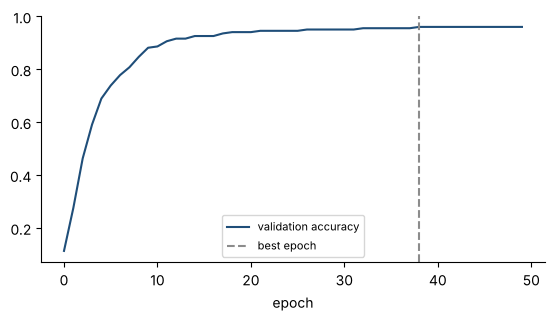

In [4]:
m_es = fit_quiet(early_stopping=True, validation_fraction=0.15, n_iter_no_change=10, max_iter=500)
m_full = fit_quiet(max_iter=500)
print("early stopping : epochs", m_es.n_iter_, "| best validation score", round(m_es.best_validation_score_, 3), "| test", round(m_es.score(Xs_te, y_te), 3))
print("no early stop  : epochs", m_full.n_iter_, "| test", round(m_full.score(Xs_te, y_te), 3))
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(m_es.validation_scores_, color=BLUE, label="validation accuracy")
ax.axvline(int(np.argmax(m_es.validation_scores_)), color=GRAY, ls="--", label="best epoch")
ax.set_xlabel("epoch"); ax.legend(fontsize=8); plt.show()

**Giải thích từng dòng**

- `early_stopping=True, validation_fraction=0.15`: tự tách 15% tập học làm **tập kiểm** (không dùng để chỉnh trọng số) và chấm điểm sau mỗi epoch.
- `n_iter_no_change=10`: nếu 10 epoch liên tiếp điểm kiểm không tốt lên thì dừng.
- `best_validation_score_`: điểm kiểm cao nhất đã thấy.
- `validation_scores_`: điểm kiểm sau mỗi epoch, để vẽ.

**Cách đọc.**
- **Con số:** dừng sớm chạy **50** epoch, điểm kiểm tốt nhất **96,1%**, điểm thi **96,7%**. Không dừng sớm chạy **172** epoch, điểm thi **97,3%**.
- **Bức tranh:** điểm kiểm tăng nhanh rồi đi ngang; đi tiếp chỉ làm mạng thuộc lòng tập học mà không tốt lên ở dữ liệu mới. Dừng sớm tiết kiệm nhiều epoch; ở đây điểm thi chênh nhau chỉ 0,7 điểm phần trăm, nằm trong mức dao động của hạt giống (chặng 4), nên lợi chính là **tiết kiệm thời gian** chứ không phải điểm cao hơn.
- **Lưu ý:** dừng sớm lấy bớt dữ liệu học làm tập kiểm, nên với dữ liệu quá ít thì cân nhắc. Đây là cùng ý với `early_stopping` của HistGradientBoosting ở E4.
- **Câu hỏi tiếp:** có cách phanh mạng ngay khi học, không cần đợi dừng không?

**Mang về chặng 3:** dừng sớm theo tập kiểm là phanh rẻ và hiệu quả.

## Chặng 3: Phanh alpha

**Câu hỏi:** phạt trọng số lớn có giúp mạng bớt học thừa không?

In [5]:
rows = []
for alpha in [0.0, 0.0001, 0.01, 0.1, 1.0, 3.0]:
    m = fit_quiet(alpha=alpha, max_iter=500)
    rows.append({"alpha": alpha, "train": round(m.score(Xs_tr, y_tr), 3), "test": round(m.score(Xs_te, y_te), 3), "epochs run": m.n_iter_, "largest |weight|": round(max(np.abs(w).max() for w in m.coefs_), 2)})
alpha_table = pd.DataFrame(rows).set_index("alpha")
alpha_table["gap"] = (alpha_table["train"] - alpha_table["test"]).round(3)
print(alpha_table.to_string())

        train   test  epochs run  largest |weight|    gap
alpha                                                    
0.0000  1.000  0.973         172              0.68  0.027
0.0001  1.000  0.973         172              0.68  0.027
0.0100  1.000  0.973         169              0.68  0.027
0.1000  1.000  0.976         169              0.65  0.024
1.0000  0.999  0.980         298              0.62  0.019
3.0000  0.991  0.978         346              0.56  0.013


**Giải thích từng dòng**

- `alpha=alpha`: hệ số phạt L2 (như Ridge ở B6): thêm vào sai số một khoản tỷ lệ với bình phương trọng số, nên trọng số lớn bị "phạt". `alpha` lớn thì phanh mạnh.
- `max(np.abs(w).max() for w in m.coefs_)`: trọng số lớn nhất trong mạng: phanh mạnh thì con số này nhỏ lại.
- `train - test`: khoảng cách học trừ thi: thước đo học thừa.

**Cách đọc.**
- **Con số:** `alpha` = 0 cho khoảng cách học trừ thi **2,7** điểm; `alpha` = 1 cho **1,9** điểm; `alpha` = 3 cho **1,3** điểm. Điểm thi cao nhất ở `alpha` = **1.0** (**98,0%**). Trọng số lớn nhất giảm từ **0,68** xuống **0,56**.
- **Bức tranh:** `alpha` tăng thì trọng số co lại, điểm học hạ xuống, khoảng cách học trừ thi thu hẹp. Điểm thi chỉ nhích lên vài phần mười điểm phần trăm (nằm trong mức dao động), còn xu hướng thu hẹp khoảng cách học trừ thi thì rõ hơn: phanh ở đây đổi lấy độ ổn định chứ không đổi lấy điểm cao hơn nhiều. Cùng quy luật với Ridge (B6) và độ sâu cây (D2).
- **Quy tắc đọc:** `alpha` là một siêu tham số: chọn bằng kiểm định chéo (D4), thử theo lũy thừa của 10.

**Mang về chặng 4:** phanh `alpha` đổi lấy điểm học thấp hơn để có khoảng cách học và thi nhỏ hơn.

## Chặng 4: Nhiều hạt giống, lấy trung bình

**Câu hỏi:** điểm dao động giữa các hạt giống bao nhiêu, và lấy trung bình nhiều mạng có tốt hơn không?

In [6]:
nets = [fit_quiet(random_state=s, early_stopping=True, max_iter=500) for s in range(10)]
single = np.array([n.score(Xs_te, y_te) for n in nets])
proba = np.mean([n.predict_proba(Xs_te) for n in nets[:5]], axis=0)
avg5 = float((proba.argmax(axis=1) == y_te).mean())
proba10 = np.mean([n.predict_proba(Xs_te) for n in nets], axis=0)
avg10 = float((proba10.argmax(axis=1) == y_te).mean())
print("single network test accuracy over 10 seeds: mean", round(single.mean(), 4), "min", round(single.min(), 4), "max", round(single.max(), 4))
print("average of 5 networks :", round(avg5, 4), "| average of 10 networks:", round(avg10, 4))

single network test accuracy over 10 seeds: mean 0.9513 min 0.9267 max 0.9622
average of 5 networks : 0.9667 | average of 10 networks: 0.9689


**Giải thích từng dòng**

- `for s in range(10)`: mười mạng cùng cấu hình, khác hạt giống khởi đầu.
- `n.predict_proba(Xs_te)`: xác suất mỗi mạng dự đoán cho từng ảnh thi.
- `np.mean([...], axis=0)`: trung bình xác suất của các mạng (như bỏ phiếu mềm ở E5), rồi lấy nhóm có xác suất cao nhất.

**Cách đọc.**
- **Con số:** mười mạng đơn cho điểm thi từ **92,7%** đến **96,2%** (trung bình **95,1%**). Trung bình xác suất 5 mạng: **96,7%**; 10 mạng: **96,9%**.
- **Bức tranh:** mỗi hạt giống là một lần thử có may rủi; điểm dao động cỡ **3,6** điểm phần trăm giữa các mạng. Trung bình nhiều mạng cao hơn mức trung bình của mạng đơn và ổn định hơn, vì lỗi ngẫu nhiên của từng mạng bù trừ nhau (cùng lý do rừng thắng cây đơn ở E2).
- **Quy tắc đọc:** báo cáo điểm kèm khoảng dao động qua nhiều hạt giống; muốn ổn định thì lấy trung bình vài mạng.

**Mang về chặng 5:** nhiều hạt giống để đo may rủi, và trung bình hóa để giảm nó.

## Chặng 5: Dữ liệu ít thì mạng học thừa

**Câu hỏi:** mạng nơ-ron cần nhiều dữ liệu cỡ nào?

In [7]:
from sklearn.linear_model import LogisticRegression
rows = []
for n in [60, 150, 400, 900, len(Xs_tr)]:
    sub = np.random.RandomState(0).choice(len(Xs_tr), n, replace=False)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        net = MLPClassifier(hidden_layer_sizes=(64,), alpha=0.1, max_iter=500, random_state=0).fit(Xs_tr[sub], y_tr[sub])
        lr_m = LogisticRegression(max_iter=1000).fit(Xs_tr[sub], y_tr[sub])
    rows.append({"training rows": n, "MLP train": round(net.score(Xs_tr[sub], y_tr[sub]), 3), "MLP test": round(net.score(Xs_te, y_te), 3), "logistic test": round(lr_m.score(Xs_te, y_te), 3)})
size_curve = pd.DataFrame(rows).set_index("training rows")
print(size_curve.to_string())

               MLP train  MLP test  logistic test
training rows                                    
60                   1.0     0.831          0.844
150                  1.0     0.896          0.911
400                  1.0     0.949          0.949
900                  1.0     0.969          0.958
1347                 1.0     0.978          0.969


**Giải thích từng dòng**

- `np.random.RandomState(0).choice(len(Xs_tr), n, replace=False)`: lấy ngẫu nhiên `n` dòng từ tập học để mô phỏng "chỉ có từng ấy dữ liệu".
- `MLPClassifier(..., alpha=0.1, ...)`: mạng 64 nơ-ron với phanh vừa phải (chặng 3).
- `LogisticRegression(max_iter=1000)`: mô hình đơn giản làm mốc so sánh (như luật đơn giản ở F6): mạng có xứng với độ phức tạp thêm vào không.

**Cách đọc.**
- **Con số:** với **60** dòng học, mạng đạt thi **83,1%** (logistic **84,4%**); với toàn bộ **1347** dòng, mạng **97,8%** (logistic **96,9%**).
- **Bức tranh:** điểm học của mạng luôn cao (nó thuộc lòng được cả tập nhỏ), còn điểm thi tăng dần theo lượng dữ liệu. Mạng chỉ thắng logistic ở các cỡ dữ liệu **[900, 1347]**; ở các cỡ còn lại nó thua hoặc hòa, tức là **chưa cần mạng**.
- **Quy tắc đọc:** luôn so với mô hình đơn giản (C1) làm mốc. Mạng nơ-ron chỉ đáng giá khi dữ liệu đủ nhiều hoặc đường ranh giới đủ phức tạp (như hai hình trăng ở G1).

**Mang về:** vặn tốc độ học nhìn đường loss, dừng sớm theo tập kiểm, phanh `alpha`, chạy nhiều hạt giống, và so với mô hình đơn giản.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Một lần chạy chưa đủ kết luận; điểm học chói, điểm thi kém là học thừa. |
| 1 | Tốc độ học vừa phải; vẽ đường loss để chẩn đoán. |
| 2 | Dừng sớm theo tập kiểm: phanh rẻ và hiệu quả. |
| 3 | alpha phạt trọng số lớn, thu hẹp khoảng cách học và thi. |
| 4 | Chạy nhiều hạt giống để đo may rủi; trung bình nhiều mạng để giảm nó. |
| 5 | Dữ liệu ít thì mạng dễ học thừa; luôn so với mô hình đơn giản. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Bước chân xuống núi | tốc độ học | `learning_rate_init` |
| Biết lúc nào nên ngừng | dừng sớm | `early_stopping` |
| Đợi bao nhiêu lần không khá hơn thì dừng | độ kiên nhẫn | `n_iter_no_change` |
| Phạt trọng số lớn | điều chuẩn L2 | `alpha` |
| Đường đi của sai số | đường loss | `loss_curve_` |
| Nhiều mạng bỏ phiếu | trung bình hóa | `predict_proba` rồi `mean` |

**Thử thách tự làm**

1. Ở chặng 1, thêm `solver="sgd"` với `momentum=0.9`. Đường loss khác `adam` ra sao?
2. Ở chặng 2, đổi `n_iter_no_change` thành 3 và 30. Điểm thi và số epoch đổi thế nào?
3. Ở chặng 3, kết hợp `alpha=1` với `hidden_layer_sizes=(256,)`. Mạng lớn có phanh có hơn mạng nhỏ không phanh?
4. Ở chặng 5, thêm cột `StandardScaler` vào một `Pipeline` và chạy lại bằng `cross_val_score` thay cho một lần chia.

**Checklist năng lực** (tự tick khi làm được)

- [ ] Đọc được đường loss để chẩn đoán tốc độ học.
- [ ] Dùng dừng sớm và hiểu nó lấy bớt dữ liệu.
- [ ] Chọn alpha bằng kiểm định chéo.
- [ ] Báo cáo điểm qua nhiều hạt giống.
- [ ] So mạng với mô hình đơn giản làm mốc.

## Phần thưởng (Tip pro): Sang G3: chọn cột cho mô hình


Mạng nơ-ron khéo léo nhưng "ăn" nhiều cột và nhiều dữ liệu. G3 dạy chọn cột: bỏ cột thừa, giữ cột có ích, để mọi mô hình (kể cả mạng) gọn hơn, nhanh hơn, ít học thừa hơn.